In [1]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftshift, ifftshift, fftfreq, fft

In [2]:
Exp_Data = np.loadtxt('./inputs/experimental/MotoPosition_Zyla_r0484.dat') 
# First row: MotoPosition, 
# Second row:Transmission without normalizaiton to XGM, 
# Third row:Transmission with normalizaiton to XGM
data4 = np.load('./inputs/experimental/Erik/motor_positions_um.npy')
pos_grid = np.load('./inputs/experimental/Erik/pos_grid.npy')

In [3]:
data4.shape

(20,)

In [4]:
print(Exp_Data[0,:])
print(Exp_Data[0,1:-2].shape)


[22.85185365 22.85305365 22.85365365 22.85475365 22.85565365 22.85845365
 22.85855365 22.85940365 22.86040365 22.86140365 22.86240365 22.86350365
 22.86435365 22.86535365 22.86635365 22.86735365 22.86840365 22.86915365
 22.86995365 22.87075365 22.87240365 22.87250365 22.87260365]
(20,)


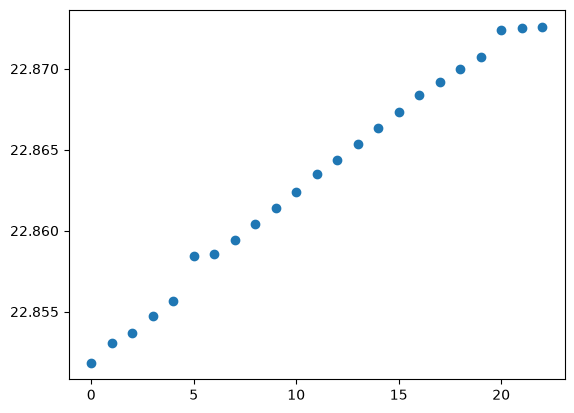

In [5]:
plt.plot(Exp_Data[0,:],'o')

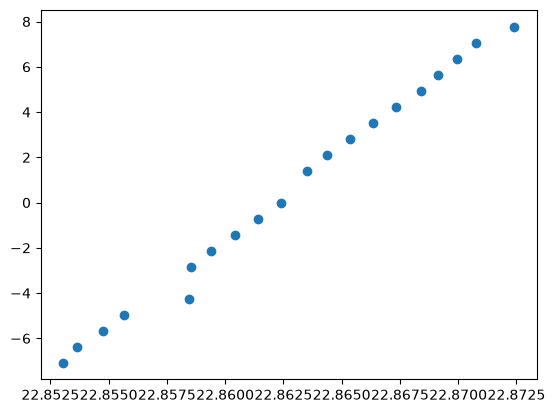

In [6]:
plt.scatter(Exp_Data[0,1:-2],data4)

In [7]:
#targetdiameter10um
#xfelfwh=7.5um
#xfelshift-10um-10um
#step0.1um


In [8]:
N0 = 2048
m = 1
cm = 1e-2
mm = 1e-3
um = 1e-6
nm = 1e-9

h = 6.62607015* 1e-34
c = 299792458
E = 8200 * 1.602176634 * 1e-19
wavelength0 = (h * c / E) *m
k0 = 2 * np.pi / wavelength0
d = 6.31 *m
fe = 0.76 *m

far_pixel_size = 6.5 *um/4
near_pixel_size = (wavelength0 * d)/(N0 * far_pixel_size)

In [9]:
(d+fe)/fe

9.302631578947368

In [10]:
def forward_propagation(k, z, wavelength, rf2, rn2, Un, ps):
   
    phase_Ou = np.exp(1j *k *z)* np.exp(1j *k *rf2 /(2 *z))
    phase_In = np.exp(1j *k *rn2 /(2 *z))
                 
    Uf = (1/(1j *wavelength *z)) *phase_Ou *fftshift(fft2(ifftshift(Un* phase_In *ps **2)))
    
    return Uf

In [11]:
far_pixel_size/near_pixel_size

5.668326231824299

In [12]:
near_pixel_size/nm

286.68074728596

In [13]:
xn = np.linspace(-N0 // 2, N0 // 2, N0) * near_pixel_size
yn = np.linspace(-N0 // 2, N0 // 2, N0) * near_pixel_size
xnm, ynm = np.meshgrid(xn, yn)
rn2 = xnm**2 + ynm**2
ra = np.sqrt(rn2)

xf = np.linspace(-N0 // 2, N0 // 2, N0) * far_pixel_size
yf = np.linspace(-N0 // 2, N0 // 2, N0) * far_pixel_size
xfm, yfm= np.meshgrid(xf, yf)
rf2 = xfm**2 + yfm**2
phio = k0 * rn2 / (2 *fe)

#FWHM = 7.5*um
FWHM = 10.0*um
sigma = FWHM / (2 * np.sqrt(2 * np.log(2)))

r_target = 5 *um
xn_b = np.where(np.abs(xn) <= r_target, xn, r_target)
target_thickness1 = 2 *np.sqrt(r_target **2 - xn_b **2)
target_thickness = np.tile(target_thickness1, (N0, 1))
cu_mu = (1/(26.05 *um))
cu_delta = 2.1401e-05
dphi_cu = -2 *np.pi *cu_delta *target_thickness/wavelength0

In [14]:
Z = np.exp(-((xnm)**2 + ynm**2) / (2 *sigma **2)) *1000

In [15]:
Pi = np.sum(Z) *near_pixel_size **2

In [16]:
#I_after_target = Z *np.exp(-cu_mu *target_thickness)

In [17]:
shift = np.linspace(0 *um, 10 *um, 51)

reuse = 1

if reuse:
    for i in shift:
        Z = np.exp(-((xnm - i)**2 + ynm**2) / (2 *sigma **2)) *1000
        i_um = (i/um)                 
        i_str = f"{i_um:.1f}"        
        Ibl = np.load(f"./Data/PB_FWHM{FWHM*1e6:0.1f}um_shift_{i_str}um.npy")
        plt.imshow(Ibl)
        #plt.savefig(f'./Figures/PB_FWHM{FWHM*1e6:0.1f}um_shift_{i_str}um.png',dpi=200,bbox_inches='tight')
else:        
    for i in shift:
        Z = np.exp(-((xnm - i)**2 + ynm**2) / (2 *sigma **2)) *1000
        I_after_target = Z *np.exp(-cu_mu *target_thickness)
        amplitude_target_t = np.sqrt(np.abs(I_after_target))
        F_target_t = amplitude_target_t *np.exp(1j *dphi_cu) *np.exp(1j *phio)
        F_lens_t = forward_propagation(k0, d, wavelength0, rf2, rn2, F_target_t, near_pixel_size)
        Ibl = np.abs(F_lens_t) **2
        #phib = np.angle(F_lens_t)

        i_um = (i/um)                 
        i_str = f"{i_um:.1f}"
        np.save(f"./Data/PB_FWHM{FWHM*1e6:0.1f}um_shift_{i_str}um.npy", Ibl)
        if i == 0:
            np.save(f"./Data/Input_FWHM{FWHM*1e6:0.1f}um_Intensity_{i_str}um.npy", Z)
        plt.imshow(Ibl)
        plt.savefig(f'./Figures/PB_FWHM{FWHM*1e6:0.1f}um_shift_{i_str}um.png',dpi=200,bbox_inches='tight')        

In [ ]:
np.sum(Z) *near_pixel_size **2

In [ ]:
plt.plot(Z[1024, 1024-128:1024+128])

In [ ]:
#amplitude_target_t = np.sqrt(np.abs(I_after_target))
#F_target_t = amplitude_target_t *np.exp(1j *dphi_cu) *np.exp(1j *phio)
#F_lens_t = forward_propagation(k0, d, wavelength0, rf2, rn2, F_target_t, near_pixel_size)
#Ibl = np.abs(F_lens_t) **2
#phib = np.angle(F_lens_t)

In [ ]:
Ibl01 = np.load(f'./Data/PB_FWHM{FWHM*1e6:0.1f}um_shift_0.0um.npy')
plt.imshow(Ibl01[1024-256:1024+256,1024-256:1024+256])

In [ ]:
#Ibl99 = np.load('PB_shift_9.9um.npy')
#plt.imshow(Ibl99[1024-256:1024+256,1024-256:1024+256])

In [ ]:
#np.sum(Ibl99) *far_pixel_size **2

In [ ]:
sh = np.linspace(0, 10, 51)
su = []

for j in sh:
    j_str = f"{j:.1f}"   # 一位小数，如 0.3
    Inte = np.load(f'./Data/PB_FWHM{FWHM*1e6:0.1f}um_shift_{j_str}um.npy')
    Po = np.sum(Inte) *far_pixel_size **2
    su.append(Po/Pi)


In [ ]:
Offset_Abs_Tra = np.vstack((sh,np.array(su),1-np.array(su)))
np.savetxt(f"Offset_Abs_Tra_FWHM{FWHM*1e6:0.1f}um.dat", Offset_Abs_Tra)

In [ ]:
fig = plt.figure(figsize=(8, 6),facecolor="w")
plt.plot(Offset_Abs_Tra[0,:], Offset_Abs_Tra[1,:],color='k',label = 'Simulation')
plt.plot(-Offset_Abs_Tra[0,:], Offset_Abs_Tra[1,:],color='k')
#plt.plot(Exp_Data[0,:], Exp_Data[2,:],color='b',label = 'Experiment')
plt.plot(data4+2, Exp_Data[2,1:-2]/4300,color='b',marker='o',label = 'Experiment')
#plt.xlim(-3,3)
plt.xlabel('XFEL Offset [$\mu$m]')
plt.ylabel('XFEL Transmission')
plt.title(f'XFEL FWHM {FWHM*1e6:0.1f}um Transmission in 10um Wire')
#plt.ylim(0,1)
plt.legend()
plt.savefig(f'./PB_FWHM{FWHM*1e6:0.1f}um_Transmission_Compare.png',dpi=200,bbox_inches='tight')

In [ ]:
plt.plot(Exp_Data[0,:], Exp_Data[2,:],color='b',label = 'Experiment')

In [ ]:
plt.plot(data4, Exp_Data[2,1:-2]/4600,color='b',label = 'Experiment')

In [ ]:
#plt.plot(data4, Exp_Data[2,:],color='b',label = 'Experiment')

In [ ]:
data4.shape

In [ ]:
Exp_Data[0,:]

In [ ]:
plt.plot(sh, su)

In [ ]:
fig = plt.figure(figsize=(8, 6),facecolor="w")
plt.plot(sh, 1 - np.array(su),color='k')
plt.plot(-sh, 1 - np.array(su),color='k')

plt.xlabel('XFEL Offset [$\mu$m]')
plt.ylabel('XFEL Absorption')
plt.title(f'XFEL FWHM {FWHM*1e6:0.1f}um Absorption in 10um Wire')
plt.savefig(f'./PB_FWHM{FWHM*1e6:0.1f}um_Absorption.png',dpi=200,bbox_inches='tight')
#plt.xlim(-3,3)

In [ ]:
fig = plt.figure(figsize=(8, 6),facecolor="w")
plt.plot(sh,  np.array(su),color='k')
plt.plot(-sh,  np.array(su),color='k')

#plt.xlim(-3,3)
plt.xlabel('XFEL Offset [$\mu$m]')
plt.ylabel('XFEL Transmission')
plt.title(f'XFEL FWHM {FWHM*1e6:0.1f}um Transmission in 10um Wire')
#plt.ylim(0,1)
plt.savefig(f'./PB_FWHM{FWHM*1e6:0.1f}um_Transmission.png',dpi=200,bbox_inches='tight')

In [ ]:
np.array(su)[-1]

In [ ]:
0.4/0.7

In [ ]:
np.array(su)

In [ ]:
np.save("PB0.1.npy", Ibl)

In [ ]:
plt.imshow(Ibl[1024-256:1024+256,1024-256:1024+256])

In [ ]:
plt.plot(Ibl[1024])

In [ ]:
#xnd = np.linspace(-N0 // 2, N0 // 2, N0) * near_pixel_size_d
ynd = np.linspace(-N0 // 2, N0 // 2, N0) * near_pixel_size_d
xndm, yndm = np.meshgrid(xnd, ynd)
rnd2 = xndm**2 + yndm**2
phiconv = -k0 * rnd2 / (2 *fdconv)

xfd = np.linspace(-N0 // 2, N0 // 2, N0) * far_pixel_size_d
yfd = np.linspace(-N0 // 2, N0 // 2, N0) * far_pixel_size_d
xfdm, yfdm = np.meshgrid(xfd, yfd)
rfd2 = xfdm**2 + yfdm**2
phiconc = k0 * rfd2 / (2 *fdconc)

In [ ]:
#CRL absorption
tmp4 = np.where(ra <= CRL_rmax, (CRL_web  + 2.0 * co * rn2) * 15, CRL_thickness)
Ilaa = Ibl *np.exp(-Be_mu *tmp4)
Iaa = np.where(ra <= CRL_rmax, Ilaa, 0)

In [ ]:
#CRL TO detector 
Fal = np.sqrt(Iaa) *np.exp(1j *phib) *np.exp(1j *phio)
Fd = forward_propagation(k0, dal, wavelength0, rf2, rn2, Fal, near_pixel_size)
Idb = np.abs(Fd) **2

In [ ]:
# Detector amplify
Fdb = np.abs(Fd) *np.exp(1j *0)
Fdbl = angular_spectrum_propagation(Fdb, od, k0, wavelength0, near_pixel_size_d)
Fdal = Fdbl *np.exp(1j *phiconv)
Fdf = forward_propagation(k0, ddal, wavelength0, rfd2, rnd2, Fdal, near_pixel_size_d)

In [ ]:
Iz = np.abs(Fdf) **2
plt.imshow(Iz)